# T-JEPA on Elliptic Bitcoin Fraud Detection (v2)

Clean version of the experiment: data processing, self-supervised pretraining, embedding extraction, fraud classifier and test evaluation.

**Pipeline**

1. Load the Elliptic features and class labels, merge on `txId`, keep labeled transactions.
2. Chronological split by `time_step`: train <= 34, validation 35-39, test >= 40.
3. Standardize features (scaler fitted on the training set only).
4. Pretrain T-JEPA with masked-feature prediction (no labels used).
5. Extract transaction embeddings with the context encoder.
6. Train an MLP fraud classifier; select the best epoch by validation Average Precision.
7. Evaluate once on the held-out test set.

**Labels:** `1` = illicit (fraud), `0` = licit.

In [11]:
# Imports, random seeds and device
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, accuracy_score, confusion_matrix, classification_report,
    precision_recall_curve,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [12]:
# Configuration: all paths and hyperparameters in one place
DATA_DIR = "/kaggle/input/datasets/ellipticco/elliptic-data-set/elliptic_bitcoin_dataset"
OUTPUT_DIR = "/kaggle/working/tjepa_elliptic_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Chronological split on time_step
TRAIN_END = 34          # train: time_step <= 34
VAL_END = 39            # validation: 35..39, test: >= 40

# T-JEPA pretraining
HIDDEN_DIM = 256
EMBEDDING_DIM = 128
N_TIME_STEPS = 50       # size of the time-step embedding table
TIME_EMB_DIM = 16
MASK_PROB = 0.30        # fraction of input features randomly zeroed
EMA_MOMENTUM = 0.996    # target-encoder moving-average momentum
PRETRAIN_EPOCHS = 20
PRETRAIN_LR = 1e-3
PRETRAIN_BATCH = 512
WEIGHT_DECAY = 1e-4

# Downstream classifier
CLS_EPOCHS = 30
CLS_LR = 1e-3
CLS_BATCH = 256
PATIENCE = 5            # early stopping on validation Average Precision
THRESHOLD = 0.50        # decision threshold for precision / recall / F1

In [13]:
# Load features and classes, merge on txId, keep labeled transactions
features = pd.read_csv(os.path.join(DATA_DIR, "elliptic_txs_features.csv"), header=None)
classes = pd.read_csv(os.path.join(DATA_DIR, "elliptic_txs_classes.csv"))

features.columns = ["txId", "time_step"] + [
    f"feature_{i}" for i in range(1, features.shape[1] - 1)
]
classes.columns = ["txId", "class"]

df = features.merge(classes, on="txId", how="inner")
df["class"] = df["class"].astype(str).str.strip()

# Elliptic classes: "1" = illicit, "2" = licit, "unknown" = unlabeled (dropped)
df = df[df["class"].isin(["1", "2"])].copy()
df["label"] = df["class"].map({"1": 1, "2": 0}).astype(int)   # 1 = fraud

df = df.sort_values(["time_step", "txId"]).reset_index(drop=True)
feature_cols = [c for c in df.columns if c.startswith("feature_")]

print("Labeled transactions:", len(df), "| features:", len(feature_cols))
print(df["label"].value_counts().to_dict())

Labeled transactions: 46564 | features: 165
{0: 42019, 1: 4545}


In [14]:
# Chronological train / validation / test split
train_df = df[df["time_step"] <= TRAIN_END].copy()
val_df = df[(df["time_step"] > TRAIN_END) & (df["time_step"] <= VAL_END)].copy()
test_df = df[df["time_step"] > VAL_END].copy()

# Standardize: the scaler is fitted on the training set only
scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[feature_cols].fillna(0)).astype(np.float32)
X_val = scaler.transform(val_df[feature_cols].fillna(0)).astype(np.float32)
X_test = scaler.transform(test_df[feature_cols].fillna(0)).astype(np.float32)

y_train = train_df["label"].to_numpy(dtype=np.int64)
y_val = val_df["label"].to_numpy(dtype=np.int64)
y_test = test_df["label"].to_numpy(dtype=np.int64)

t_train = train_df["time_step"].to_numpy(dtype=np.int64)
t_val = val_df["time_step"].to_numpy(dtype=np.int64)
t_test = test_df["time_step"].to_numpy(dtype=np.int64)

for name, X, y in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name}: {X.shape}, fraud = {int(y.sum())}")

Train: (29894, 165), fraud = 3462
Validation: (5486, 165), fraud = 447
Test: (11184, 165), fraud = 636


In [15]:
# T-JEPA model: context encoder, EMA target encoder, predictor, time-step embedding
class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, embedding_dim=128, time_emb_dim=16):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim + time_emb_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, embedding_dim),
        )

    def forward(self, x, time_embedding):
        return self.network(torch.cat([x, time_embedding], dim=1))


class TJEPA(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, embedding_dim=128,
                 n_time_steps=50, time_emb_dim=16):
        super().__init__()
        self.time_embedding = nn.Embedding(n_time_steps, time_emb_dim)
        self.context_encoder = Encoder(input_dim, hidden_dim, embedding_dim, time_emb_dim)

        # Target encoder: frozen copy of the context encoder, updated only by EMA
        self.target_encoder = copy.deepcopy(self.context_encoder)
        for p in self.target_encoder.parameters():
            p.requires_grad = False

        self.predictor = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, embedding_dim),
        )

    def forward(self, x, time_step):
        time_emb = self.time_embedding(time_step)
        z_context = self.context_encoder(x, time_emb)
        with torch.no_grad():
            z_target = self.target_encoder(x, time_emb)
        prediction = self.predictor(z_context)
        return prediction, z_target, z_context

    @torch.no_grad()
    def update_target(self, momentum=0.996):
        for p_ctx, p_tgt in zip(self.context_encoder.parameters(),
                                self.target_encoder.parameters()):
            p_tgt.data.mul_(momentum).add_(p_ctx.data, alpha=1 - momentum)

In [16]:
# Self-supervised pretraining (training transactions only, no labels)
INPUT_DIM = X_train.shape[1]

train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train), torch.tensor(t_train)),
    batch_size=PRETRAIN_BATCH, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available(),
)

model = TJEPA(INPUT_DIM, HIDDEN_DIM, EMBEDDING_DIM, N_TIME_STEPS, TIME_EMB_DIM).to(DEVICE)

optimizer = torch.optim.AdamW(
    list(model.context_encoder.parameters())
    + list(model.predictor.parameters())
    + list(model.time_embedding.parameters()),
    lr=PRETRAIN_LR, weight_decay=WEIGHT_DECAY,
)

history = []
for epoch in range(PRETRAIN_EPOCHS):
    model.train()
    total_loss = 0.0

    for xb, tb in train_loader:
        xb, tb = xb.to(DEVICE, non_blocking=True), tb.to(DEVICE, non_blocking=True)

        # Randomly zero out features, then predict the target embedding
        x_masked = xb * (torch.rand_like(xb) > MASK_PROB).float()
        prediction, target, _ = model(x_masked, tb)

        # MSE between L2-normalized prediction and target embeddings
        loss = F.mse_loss(F.normalize(prediction, dim=1), F.normalize(target, dim=1))

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        model.update_target(momentum=EMA_MOMENTUM)

        total_loss += loss.item()

    history.append(total_loss / len(train_loader))
    print(f"Epoch {epoch + 1:02d}/{PRETRAIN_EPOCHS} | loss = {history[-1]:.6f}")

torch.save({
    "model_state_dict": model.state_dict(),
    "input_dim": INPUT_DIM, "hidden_dim": HIDDEN_DIM, "embedding_dim": EMBEDDING_DIM,
    "feature_cols": feature_cols, "training_loss": history, "seed": SEED,
}, os.path.join(OUTPUT_DIR, "tjepa_elliptic_checkpoint.pth"))

Epoch 01/20 | loss = 0.003671
Epoch 02/20 | loss = 0.000745
Epoch 03/20 | loss = 0.000256
Epoch 04/20 | loss = 0.000121
Epoch 05/20 | loss = 0.000072
Epoch 06/20 | loss = 0.000048
Epoch 07/20 | loss = 0.000035
Epoch 08/20 | loss = 0.000029
Epoch 09/20 | loss = 0.000023
Epoch 10/20 | loss = 0.000020
Epoch 11/20 | loss = 0.000018
Epoch 12/20 | loss = 0.000017
Epoch 13/20 | loss = 0.000015
Epoch 14/20 | loss = 0.000014
Epoch 15/20 | loss = 0.000014
Epoch 16/20 | loss = 0.000013
Epoch 17/20 | loss = 0.000013
Epoch 18/20 | loss = 0.000013
Epoch 19/20 | loss = 0.000013
Epoch 20/20 | loss = 0.000014


In [17]:
# Extract embeddings with the pretrained context encoder (no masking)
@torch.no_grad()
def extract_embeddings(X, timesteps, batch_size=1024):
    model.eval()
    X_t = torch.tensor(X, dtype=torch.float32).to(DEVICE)
    t_t = torch.tensor(timesteps, dtype=torch.long).to(DEVICE)
    out = []
    for i in range(0, len(X_t), batch_size):
        time_emb = model.time_embedding(t_t[i:i + batch_size])
        out.append(model.context_encoder(X_t[i:i + batch_size], time_emb).cpu().numpy())
    return np.concatenate(out, axis=0)

Z_train = extract_embeddings(X_train, t_train)
Z_val = extract_embeddings(X_val, t_val)
Z_test = extract_embeddings(X_test, t_test)
print("Embeddings:", Z_train.shape, Z_val.shape, Z_test.shape)

Embeddings: (29894, 128) (5486, 128) (11184, 128)


In [18]:
# Downstream fraud classifier on the frozen embeddings
# Class imbalance is handled with a positive-class weight in the loss;
# the best epoch is chosen by validation Average Precision (early stopping).
torch.manual_seed(SEED)
np.random.seed(SEED)

class FraudClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.network(x)

Z_train_t = torch.tensor(Z_train, dtype=torch.float32)
Z_val_t = torch.tensor(Z_val, dtype=torch.float32)
Y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

classifier = FraudClassifier(Z_train_t.shape[1]).to(DEVICE)

pos = int(y_train.sum())
pos_weight = torch.tensor([(len(y_train) - pos) / pos], dtype=torch.float32, device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer_cls = torch.optim.Adam(classifier.parameters(), lr=CLS_LR, weight_decay=WEIGHT_DECAY)

cls_loader = DataLoader(TensorDataset(Z_train_t, Y_train_t), batch_size=CLS_BATCH, shuffle=True)

best_val_ap, best_state, wait = -1.0, None, 0
for epoch in range(CLS_EPOCHS):
    classifier.train()
    total_loss = 0.0
    for zb, yb in cls_loader:
        zb, yb = zb.to(DEVICE), yb.to(DEVICE)
        optimizer_cls.zero_grad()
        loss = criterion(classifier(zb), yb)
        loss.backward()
        optimizer_cls.step()
        total_loss += loss.item() * len(zb)

    classifier.eval()
    with torch.no_grad():
        val_prob = torch.sigmoid(classifier(Z_val_t.to(DEVICE))).cpu().numpy().ravel()
    val_ap = average_precision_score(y_val, val_prob)
    print(f"Epoch {epoch + 1:02d}/{CLS_EPOCHS} | loss = {total_loss / len(Z_train_t):.4f} | val AP = {val_ap:.4f}")

    if val_ap > best_val_ap:
        best_val_ap, wait = val_ap, 0
        best_state = {k: v.detach().cpu().clone() for k, v in classifier.state_dict().items()}
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping.")
            break

classifier.load_state_dict(best_state)   # restore the best validation epoch
print(f"Best validation AP: {best_val_ap:.4f}")

Epoch 01/30 | loss = 0.7540 | val AP = 0.3815
Epoch 02/30 | loss = 0.4995 | val AP = 0.4930
Epoch 03/30 | loss = 0.4527 | val AP = 0.5754
Epoch 04/30 | loss = 0.4095 | val AP = 0.5177
Epoch 05/30 | loss = 0.3810 | val AP = 0.5554
Epoch 06/30 | loss = 0.3503 | val AP = 0.5823
Epoch 07/30 | loss = 0.3288 | val AP = 0.5472
Epoch 08/30 | loss = 0.3160 | val AP = 0.5922
Epoch 09/30 | loss = 0.3021 | val AP = 0.6191
Epoch 10/30 | loss = 0.2864 | val AP = 0.5845
Epoch 11/30 | loss = 0.2748 | val AP = 0.5946
Epoch 12/30 | loss = 0.2615 | val AP = 0.6102
Epoch 13/30 | loss = 0.2597 | val AP = 0.6161
Epoch 14/30 | loss = 0.2515 | val AP = 0.5869
Early stopping.
Best validation AP: 0.6191


In [19]:
# Final evaluation on the held-out test set (used only here)
classifier.eval()
with torch.no_grad():
    test_prob = torch.sigmoid(
        classifier(torch.tensor(Z_test, dtype=torch.float32).to(DEVICE))
    ).cpu().numpy().ravel()
test_pred = (test_prob >= THRESHOLD).astype(int)

roc_auc = roc_auc_score(y_test, test_prob)
pr_auc = average_precision_score(y_test, test_prob)

print("TEST RESULTS")
print(f"ROC-AUC:                    {roc_auc:.4f}")
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")
print(f"Precision: {precision_score(y_test, test_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, test_pred, zero_division=0):.4f}")
print(f"F1:        {f1_score(y_test, test_pred, zero_division=0):.4f}")
print(f"Accuracy:  {accuracy_score(y_test, test_pred):.4f}")
print("\nConfusion matrix:\n", confusion_matrix(y_test, test_pred))
print("\n", classification_report(y_test, test_pred,
      target_names=["Licit (0)", "Illicit (1)"], zero_division=0))

# Save predictions, metrics and classifier weights
pd.DataFrame({
    "txId": test_df["txId"].values, "time_step": t_test, "y_true": y_test,
    "fraud_probability": test_prob, "predicted_label": test_pred,
}).to_csv(os.path.join(OUTPUT_DIR, "tjepa_elliptic_test_predictions.csv"), index=False)

pd.DataFrame([{
    "ROC-AUC": roc_auc, "PR-AUC": pr_auc,
    "Precision@0.5": precision_score(y_test, test_pred, zero_division=0),
    "Recall@0.5": recall_score(y_test, test_pred, zero_division=0),
    "F1@0.5": f1_score(y_test, test_pred, zero_division=0),
    "Test samples": len(y_test), "Fraud samples": int(y_test.sum()),
}]).to_csv(os.path.join(OUTPUT_DIR, "tjepa_elliptic_metrics.csv"), index=False)

torch.save({"classifier_state_dict": classifier.state_dict(),
            "embedding_dim": Z_train.shape[1], "threshold": THRESHOLD},
           os.path.join(OUTPUT_DIR, "tjepa_elliptic_classifier.pth"))

TEST RESULTS
ROC-AUC:                    0.8164
PR-AUC (Average Precision): 0.4854
Precision: 0.1812
Recall:    0.6745
F1:        0.2857
Accuracy:  0.8082

Confusion matrix:
 [[8610 1938]
 [ 207  429]]

               precision    recall  f1-score   support

   Licit (0)       0.98      0.82      0.89     10548
 Illicit (1)       0.18      0.67      0.29       636

    accuracy                           0.81     11184
   macro avg       0.58      0.75      0.59     11184
weighted avg       0.93      0.81      0.85     11184



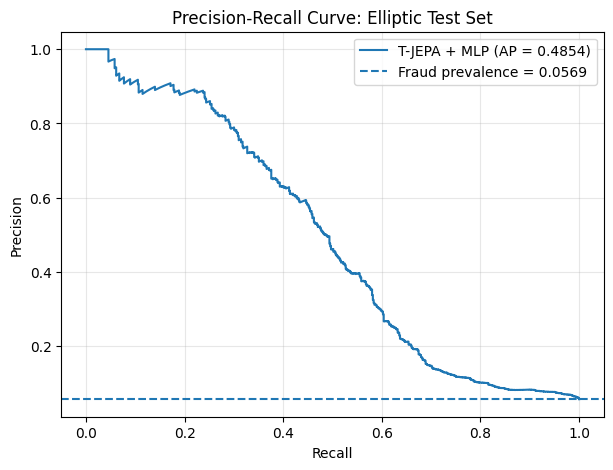

In [20]:
# Optional: precision-recall curve on the test set
precision, recall, _ = precision_recall_curve(y_test, test_prob)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"T-JEPA + MLP (AP = {pr_auc:.4f})")
plt.axhline(y_test.mean(), linestyle="--", label=f"Fraud prevalence = {y_test.mean():.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: Elliptic Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, "tjepa_elliptic_pr_curve.png"), dpi=300, bbox_inches="tight")
plt.show()